In [142]:
import pandas as pd
import numpy as np
import random
from Bio import SeqIO 

# A small constant to prevent log(0) errors
EPSILON = 1e-9

def calculate_cleavage_score(cleavage_preds, segments, core_len = 9):
    """
    Calculates a specialized cleavage score for a generic vaccine construct.

    Args:
        cleavage_preds: A NumPy array of cleavage probabilities for the full sequence.
        segments: A list of tuples, where each tuple is (segment_name, segment_length).
                  Example: [('Leader', 5), ('Linker1', 4), ('Epitope1', 15)]
        core_len: The length of the core binding motif to protect within 'Epitope' segments.

    Returns:
        The final composite cleavage score.
    """
    score_protection = 0.0
    score_processing = 0.0
    current_pos = 0

    for seg_name, seg_len in segments:
        if seg_len == 0:
            continue
        
        # Isolate the predictions for the current segment
        seg_preds = cleavage_preds[current_pos : current_pos + seg_len]
        #print(seg_preds)
        # Apply scoring logic based on segment name
        if 'epitope' in seg_name.lower():
            # --- Epitope Segment: Protect the core, reward flank cleavage ---
            core_offset = (seg_len - core_len) // 2
            core_start_local = core_offset
            core_end_local = core_start_local + core_len
            
            # Penalize cleavage within the core motif
            core_preds = seg_preds[core_start_local : core_end_local - 1]
            score_protection += np.log(1 - core_preds + EPSILON).sum()
            
            # Reward cleavage in the flanking regions
            flank_preds = np.concatenate([
                seg_preds[0 : core_start_local],
                seg_preds[core_end_local - 1 : seg_len]
            ])
            #print(flank_preds)
            if flank_preds.size > 0:
                score_processing += np.log(flank_preds.max() + EPSILON)
        else:
            # --- Other Segments (Linker, Leader, etc.): Reward cleavage ---
            if seg_preds.size > 0:
                score_processing += np.log(seg_preds.max() + EPSILON)
                #score_processing += np.log(seg_preds.sum() + EPSILON)

        # Move to the start of the next segment
        current_pos += seg_len
        
    return score_protection + score_processing


from Bio.SeqUtils.ProtParam import ProteinAnalysis

def analyze_vaccine_candidate(protein_sequence: str):
    """
    Calcula y devuelve las propiedades fisicoquímicas clave de una secuencia de proteína.

    Esta función utiliza Bio.SeqUtils.ProtParam de Biopython, que replica los cálculos
    de la herramienta ProtParam de ExPASy. Es ideal para el primer cribado de
    candidatos a vacunas multiepitópicas.

    Args:
        protein_sequence (str): La secuencia de aminoácidos de la vacuna candidata.

    Returns:
        dict: Un diccionario con las propiedades fisicoquímicas calculadas.
    """
    sequence = protein_sequence.strip().replace("\n", "")
    analysed_seq = ProteinAnalysis(sequence)

    molecular_weight = analysed_seq.molecular_weight()
    isoelectric_point = analysed_seq.isoelectric_point()
    instability_index = analysed_seq.instability_index()
    gravy = analysed_seq.gravy()

    return (molecular_weight,isoelectric_point,instability_index,gravy)


In [65]:
cleavage_df = pd.read_csv("../results/Q76R36_cleavage_results_5000.csv")
fasta_constructs = SeqIO.to_dict(SeqIO.parse("../results/Q76R36_constructs_5000.fasta", "fasta"))

In [67]:
seq_scores = []
for protid, protdf in cleavage_df.groupby("prot_id"):
    segments= [('Epitope1',9),('Linker1', 4), ('Epitope2', 9)]

    pred = protdf.prediction
    vax_process_score = calculate_cleavage_score(pred, segments)
    seq_scores.append((protid,vax_process_score, protdf))
construct_scored = sorted(seq_scores, key=lambda x: x[1],reverse=True)


In [157]:
construct_scored[0]

('construct5851|RIAW',
 -8.611076264375955,
                    prot_id  position      window  prediction
 118690  construct5851|RIAW         1  XXXXXLVVAA    0.423641
 118691  construct5851|RIAW         2  XXXXLVVAAS    0.221722
 118692  construct5851|RIAW         3  XXXLVVAASI    0.363869
 118693  construct5851|RIAW         4  XXLVVAASII    0.205982
 118694  construct5851|RIAW         5  XLVVAASIIG    0.258905
 118695  construct5851|RIAW         6  LVVAASIIGR    0.010425
 118696  construct5851|RIAW         7  VVAASIIGRI    0.199687
 118697  construct5851|RIAW         8  VAASIIGRIA    0.076218
 118698  construct5851|RIAW         9  AASIIGRIAW    0.027073
 118699  construct5851|RIAW        10  ASIIGRIAWD    0.185414
 118700  construct5851|RIAW        11  SIIGRIAWDP    0.270940
 118701  construct5851|RIAW        12  IIGRIAWDPL    0.037644
 118702  construct5851|RIAW        13  IGRIAWDPLV    0.799502
 118703  construct5851|RIAW        14  GRIAWDPLVV    0.022023
 118704  construct5851|RIA

In [158]:
[data[2]["window"].iloc[12] for data in construct_scored]

['IGRIAWDPLV',
 'SIASEWLVVA',
 'SIHETWLVVA',
 'SIRVEWLVVA',
 'IGRLSWDPLV',
 'SIMQSWLVVA',
 'SIAMSWLVVA',
 'SISHTWLVVA',
 'IGAMSWDPLV',
 'SIKTSWLVVA',
 'SIGMSYLVVA',
 'SIAQQYLVVA',
 'IGRVEWDPLV',
 'SIPMTWLVVA',
 'SIHRTWLVVA',
 'SIAESWLVVA',
 'IGRAQWDPLV',
 'IGGITYDPLV',
 'SIRIAWLVVA',
 'SIKATWLVVA',
 'IGGMSYDPLV',
 'SIAVNWLVVA',
 'SIGSTWLVVA',
 'SIQQSYLVVA',
 'SINISWLVVA',
 'SIHSTWLVVA',
 'IGMMTYDPLV',
 'SIALNWLVVA',
 'SINQQYLVVA',
 'SINEEWLVVA',
 'SIREYMLVVA',
 'SIQLTWLVVA',
 'SIPQSWLVVA',
 'SIRLSWLVVA',
 'SIGLTWLVVA',
 'SIRAQWLVVA',
 'IGQRQWDPLV',
 'IGHLEWDPLV',
 'IGGLTWDPLV',
 'SIMHNWLVVA',
 'SIAEEYLVVA',
 'SIPEEWLVVA',
 'SIHTQWLVVA',
 'SIKMAMLVVA',
 'SIHLEWLVVA',
 'SIGQTYLVVA',
 'IGALNWDPLV',
 'IGPMTWDPLV',
 'IGSSTYDPLV',
 'SIQTQWLVVA',
 'SIMVHWLVVA',
 'SINEAWLVVA',
 'IGGSTWDPLV',
 'SILMTWLVVA',
 'SIHASWLVVA',
 'SISHQYLVVA',
 'IGRRGQDPLV',
 'SIMTNWLVVA',
 'SIQQEFLVVA',
 'IGRVDWDPLV',
 'IGAVNWDPLV',
 'SIGMSFLVVA',
 'SITESWLVVA',
 'SISMAWLVVA',
 'SIRPQWLVVA',
 'IGHIHYDPLV',
 'SINDNWLV

In [41]:
# construct_scored = sorted(seq_scores, key=lambda x: x[1],reverse=True)
# top_construct = construct_scored[0]
# worst_construct = construct_scored[-1]

In [77]:
# top_construct,worst_score

## plot
Q76R36_E1_67,DPLVVAASI,I
Q76R36_E1_31,LVVAASIIG,II

In [134]:
from dna_features_viewer import GraphicFeature, GraphicRecord
import matplotlib.pyplot as plt

color_map = {'CALNN':'#ffcccc','linker1':'#ffcccc','linker2':'#ffcccc','epitopeCD8':'gold',
                 'epitopeCD4':'green','CPP':'#ccccff'}
def get_GraphicFeatures(d):
    
    record_features = list()
    s = 0
    e = 0
    for fname,fseq in d.items(): 
        e += len(fseq)

        gf = GraphicFeature(start=s, end=e, strand=0, color=color_map[fname],label=fname)
        record_features.append(gf)

        s = e
    return record_features

def plot_seqCleavage(dict_construct,cleavage_data, tag="PeptideCD8-CPP"):
    
    sequence = ''.join(dict_construct.values())
    
    features = get_GraphicFeatures(dict_construct)
    record = GraphicRecord(sequence=sequence, features=features)
    
    fig, (ax1, ax2) = plt.subplots(
    2, 1, figsize=(14, 3), sharex=True, gridspec_kw={"height_ratios": [2, 1]}
    )

    record.plot(ax=ax1,figure_width=12,figure_height=2,with_ruler=False)
    record.plot_sequence(ax1,guides_intensity=0.5)

    colormat=np.where(cleavage_data["prediction"]>=0.5,'r','black')
    ax2.bar(cleavage_data["position"] - 1,cleavage_data["prediction"],color=colormat,width=0.7)
    ax2.set_ylim(0,1)
    ax1.set_title(f"Cleavage predictions for {tag}")
    plt.savefig(f'{tag}.png', bbox_inches='tight')

## Prediccion de clivado para Top5 secuencias (score de procesamiento). Diseño E-L-E

In [123]:
q95 = pd.DataFrame([s[1] for s in construct_scored]).quantile(0.95)[0]
construct_scored_q95 = list(filter(lambda x: x[1]>=q95,construct_scored))

construct4250|ASEW DPLVVAASIASEWLVVAASIIG
Molecular Weight (Da):2181.53 pI: 4.05 Instability Index: 17.08 GRAVY: 1.573
construct2942|HETW DPLVVAASIHETWLVVAASIIG
Molecular Weight (Da):2261.61 pI: 4.35 Instability Index: 13.93 GRAVY: 1.350
construct626|RVEW DPLVVAASIRVEWLVVAASIIG
Molecular Weight (Da):2278.69 pI: 4.37 Instability Index: 8.32 GRAVY: 1.514
construct7795|RLSW LVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):2250.68 pI: 5.84 Instability Index: 9.55 GRAVY: 1.618


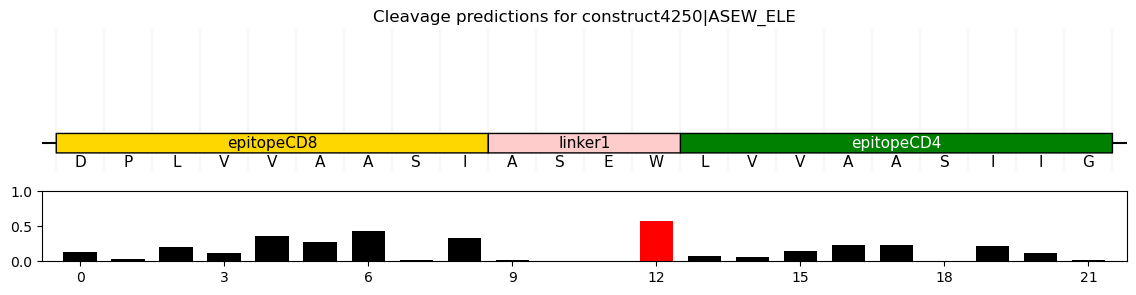

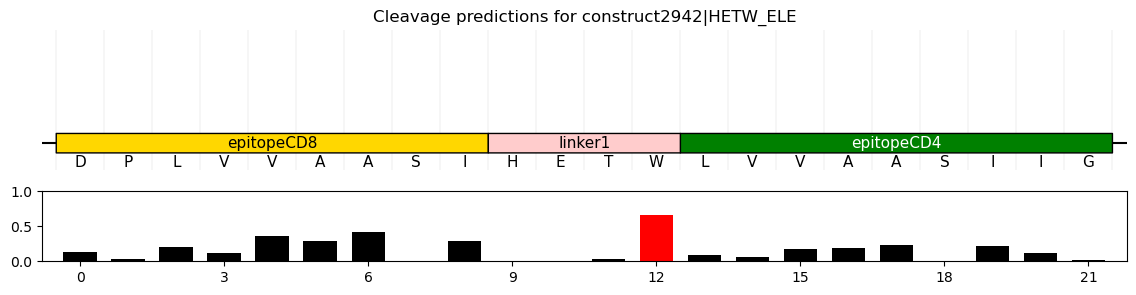

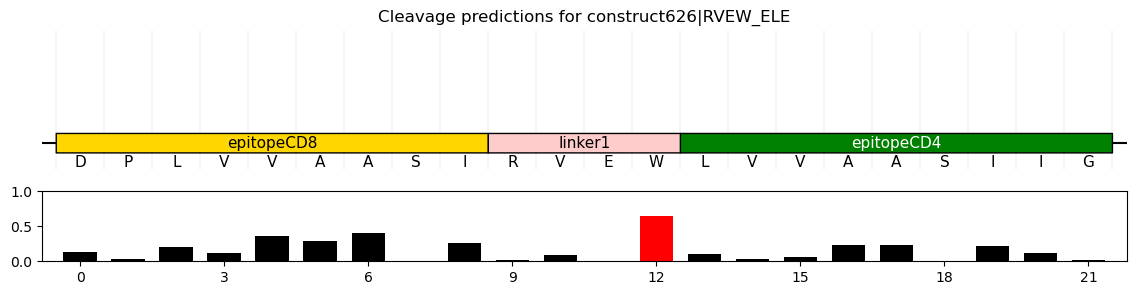

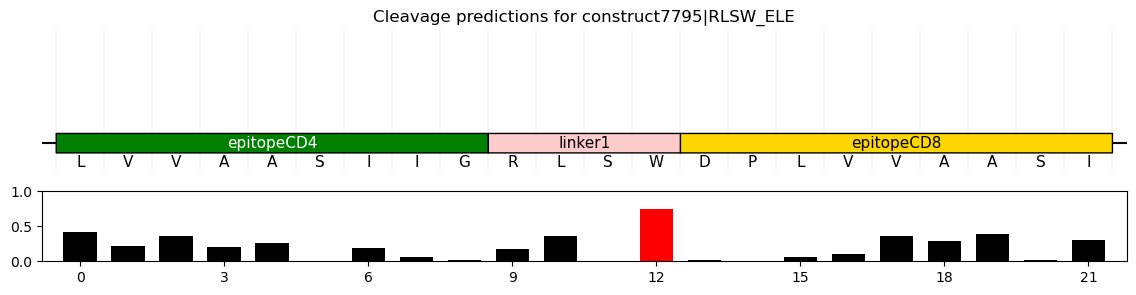

In [141]:
# plot top 5 
for data in construct_scored_q95[:5]:
    seqname = data[0]
    seqscore = round(data[1],4)
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    if sequence.startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD8"] = sequence[9+4:9+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD4"] = sequence[9+4:9+4+9]
    
    properties = analyze_vaccine_candidate(sequence)
    if properties[2] < 40 and properties[3] <= 1.7:
        print(seqname, sequence)
        plot_seqCleavage(constructELE, data[2], tag=f"{seqname}_ELE")
        print(f"Molecular Weight (Da):{properties[0]:.2f}",
        f"pI: {properties[1]:.2f}",
        f"Instability Index: {properties[2]:.2f}",
        f"GRAVY: {properties[3]:.3f}")

(array([  2.,   2.,   3.,   6.,  15.,  20.,  14.,  28.,  39.,  40.,  55.,
         66.,  88., 109., 111., 125., 142., 184., 242., 316., 419., 489.,
        563., 708., 744., 793., 770., 774., 683., 617., 536., 440., 308.,
        233., 141.,  92.,  53.,  19.,  14.,   3.]),
 array([-13.56905513, -13.44510566, -13.32115619, -13.19720672,
        -13.07325725, -12.94930777, -12.8253583 , -12.70140883,
        -12.57745936, -12.45350989, -12.32956042, -12.20561094,
        -12.08166147, -11.957712  , -11.83376253, -11.70981306,
        -11.58586359, -11.46191411, -11.33796464, -11.21401517,
        -11.0900657 , -10.96611623, -10.84216675, -10.71821728,
        -10.59426781, -10.47031834, -10.34636887, -10.2224194 ,
        -10.09846992,  -9.97452045,  -9.85057098,  -9.72662151,
         -9.60267204,  -9.47872257,  -9.35477309,  -9.23082362,
         -9.10687415,  -8.98292468,  -8.85897521,  -8.73502574,
         -8.61107626]),
 <BarContainer object of 40 artists>)

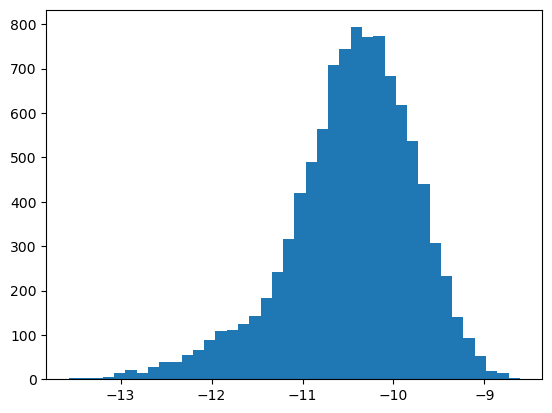

In [70]:
plt.hist([s[1] for s in construct_scored],bins=40)

## Prediccion de clivado para worst5 secuencias (score de procesamiento)

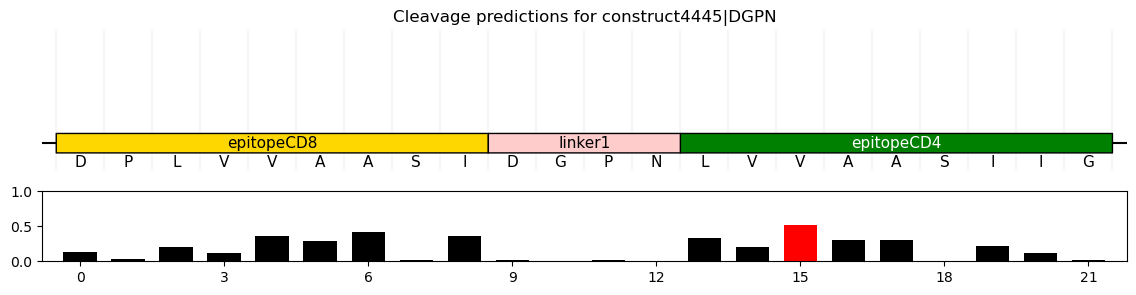

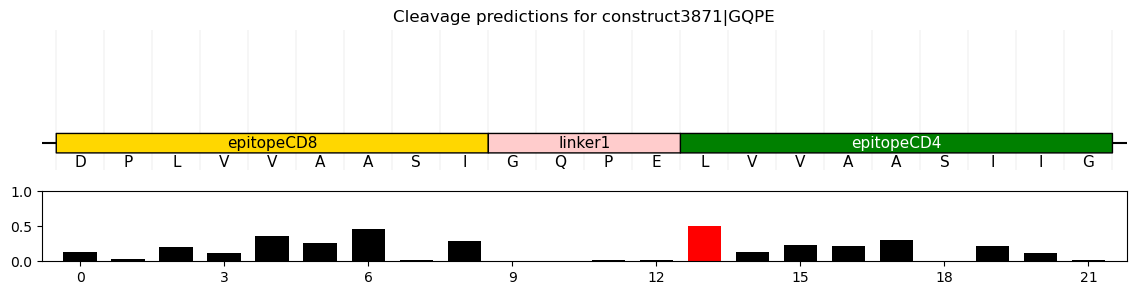

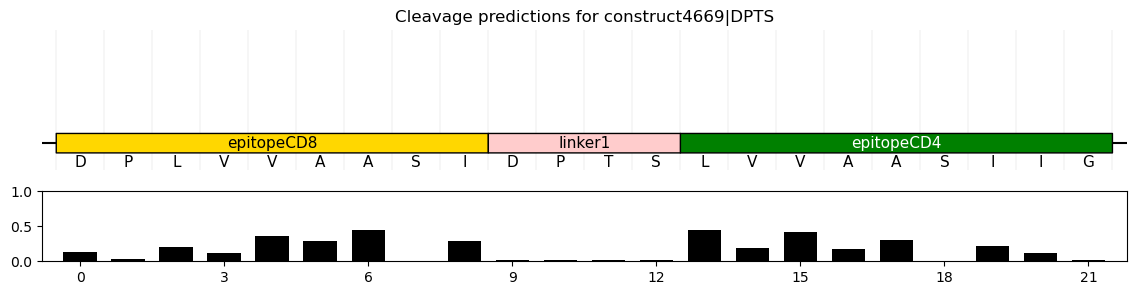

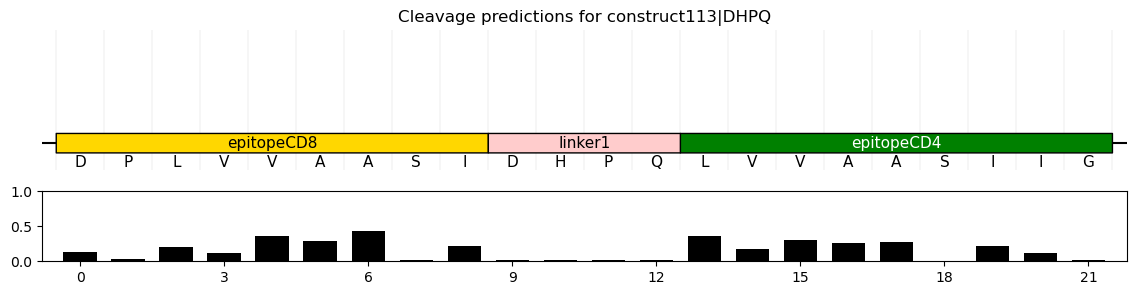

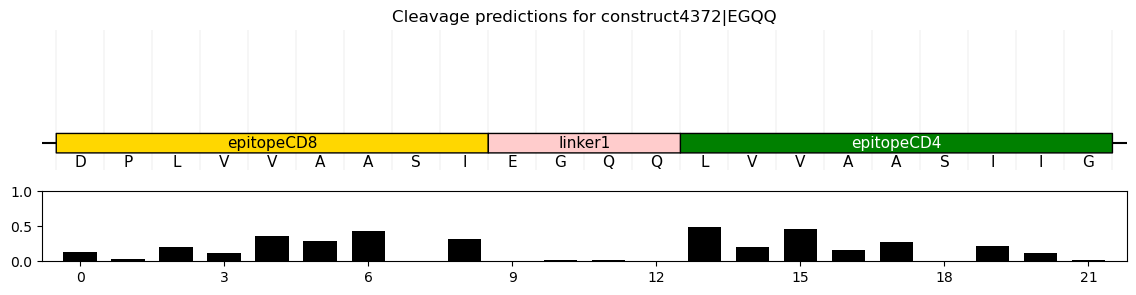

In [71]:
for data in construct_scored[-5:]:
    seqname = data[0]
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    if sequence.startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD8"] = sequence[9+4:9+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD4"] = sequence[9+4:9+4+9]

    plot_seqCleavage(constructELE, data[2], tag=f"{seqname}")

## Prediccion de clivado para Random5 secuencias (score de procesamiento)

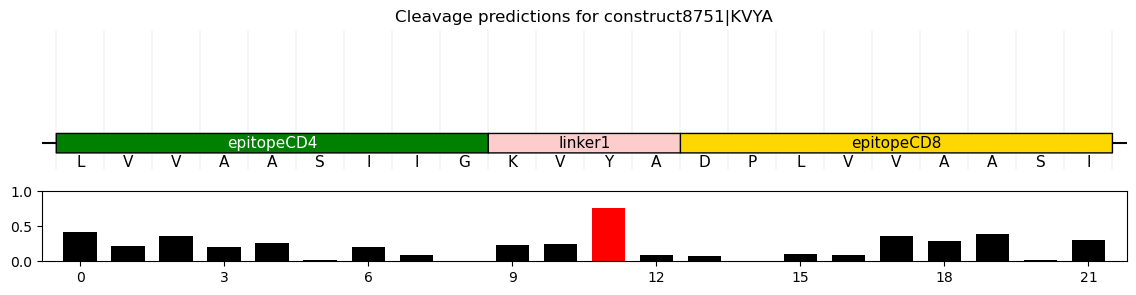

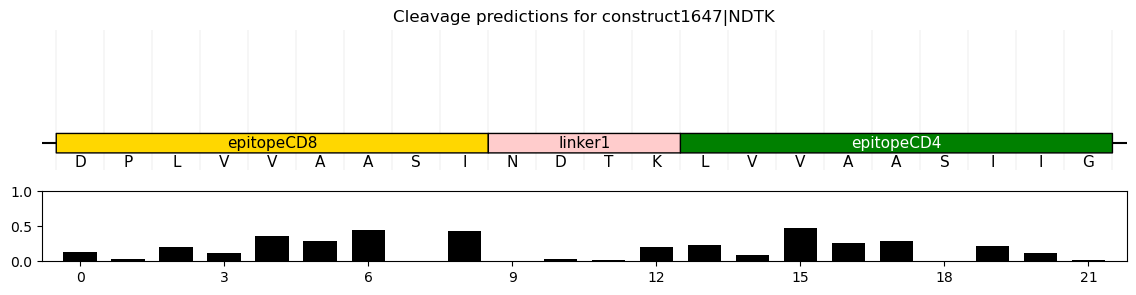

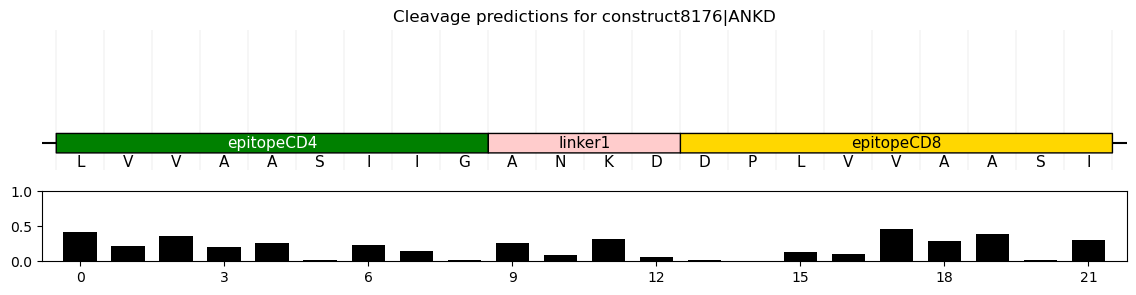

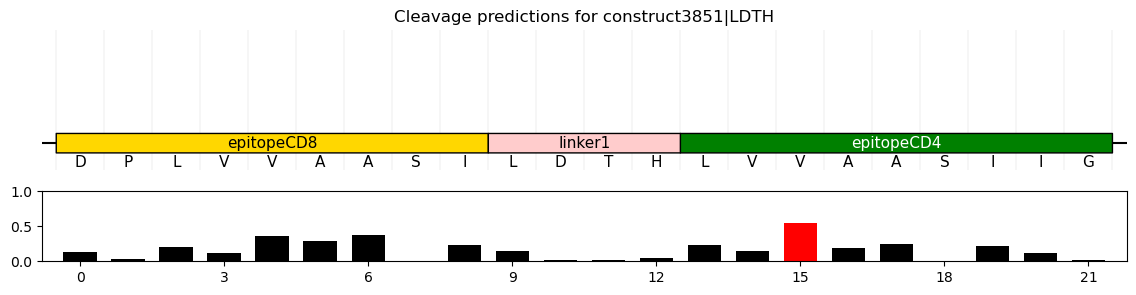

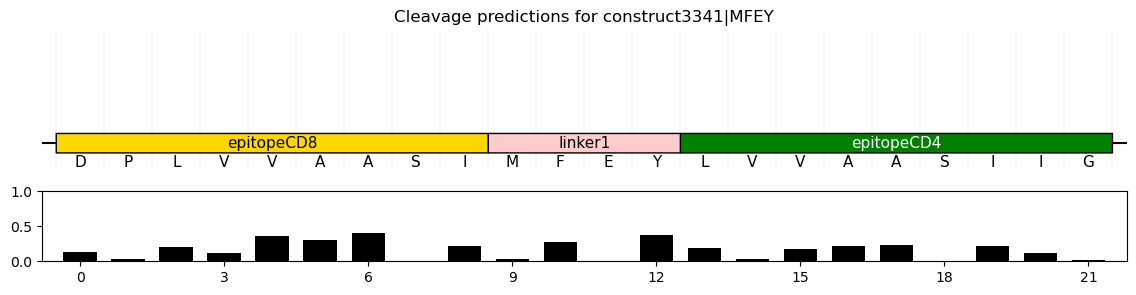

In [73]:
for data in random.choices(construct_scored[1000:],k=5):
    seqname = data[0]
    sequence = str(fasta_constructs[seqname].seq)
    
    constructELE = dict()
    if sequence.startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD8"] = sequence[9+4:9+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[:9]
        constructELE["linker1"] = sequence[9:9+4]
        constructELE["epitopeCD4"] = sequence[9+4:9+4+9]

    plot_seqCleavage(constructELE, data[2], tag=f"{seqname}")

In [53]:
seq = str(fasta_constructs["construct7749|WVSS"].seq)
pred = next(filter(lambda s: s[0]=="construct7749|WVSS",construct_scored,))[2].prediction
seq

'LVVAASIIGWVSSDPLVVAASI'

In [52]:
pred

,prot_id,position,window,prediction
165066,construct7749|WVSS,1,XXXXXLVVAA,0.423641
165067,construct7749|WVSS,2,XXXXLVVAAS,0.221722
165068,construct7749|WVSS,3,XXXLVVAASI,0.363869
165069,construct7749|WVSS,4,XXLVVAASII,0.205982
165070,construct7749|WVSS,5,XLVVAASIIG,0.258905
165071,construct7749|WVSS,6,LVVAASIIGW,0.013127
165072,construct7749|WVSS,7,VVAASIIGWV,0.132007
165073,construct7749|WVSS,8,VAASIIGWVS,0.047270
165074,construct7749|WVSS,9,AASIIGWVSS,0.004742
165075,construct7749|WVSS,10,ASIIGWVSSD,0.720301


In [56]:
segments= [('Epitope1',9),('Linker1', 4), ('Epitope2', 9)]
calculate_cleavage_score(pred, segments)

165066    0.423641
165067    0.221722
165068    0.363869
165069    0.205982
165070    0.258905
165071    0.013127
165072    0.132007
165073    0.047270
165074    0.004742
Name: prediction, dtype: float64
[0.00474182]
165075    0.720301
165076    0.126342
165077    0.015306
165078    0.011987
Name: prediction, dtype: float64
165079    0.081190
165080    0.009360
165081    0.106939
165082    0.094334
165083    0.410026
165084    0.292405
165085    0.385951
165086    0.013492
165087    0.304091
Name: prediction, dtype: float64
[0.3040907]


-10.53847169658075

In [70]:
constructELE = dict()
constructELE["epitopeCD4"] = seq[:9]
constructELE["linker1"] = seq[9:9+4]
constructELE["epitopeCD8"] = seq[9+4:9+4+9]


In [72]:
top_construct[2]

,prot_id,position,window,prediction
118690,construct5851|RIAW,1,XXXXXLVVAA,0.423641
118691,construct5851|RIAW,2,XXXXLVVAAS,0.221722
118692,construct5851|RIAW,3,XXXLVVAASI,0.363869
118693,construct5851|RIAW,4,XXLVVAASII,0.205982
118694,construct5851|RIAW,5,XLVVAASIIG,0.258905
118695,construct5851|RIAW,6,LVVAASIIGR,0.010425
118696,construct5851|RIAW,7,VVAASIIGRI,0.199687
118697,construct5851|RIAW,8,VAASIIGRIA,0.076218
118698,construct5851|RIAW,9,AASIIGRIAW,0.027073
118699,construct5851|RIAW,10,ASIIGRIAWD,0.185414


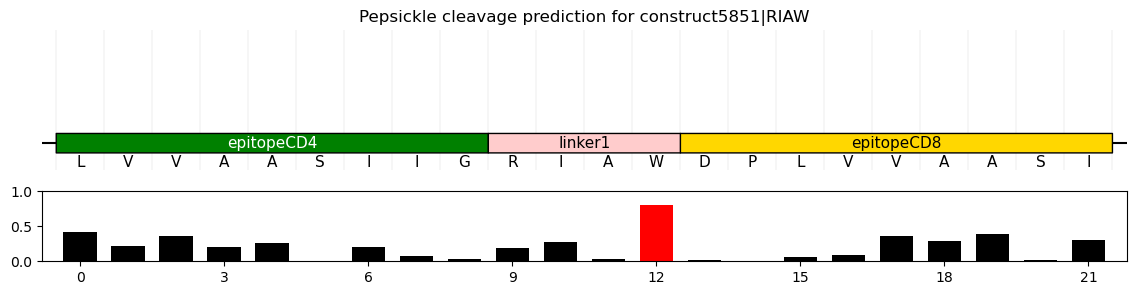

In [71]:
plot_seqCleavage(constructELE,top_construct[2],tag=f"{top_construct[0]}")

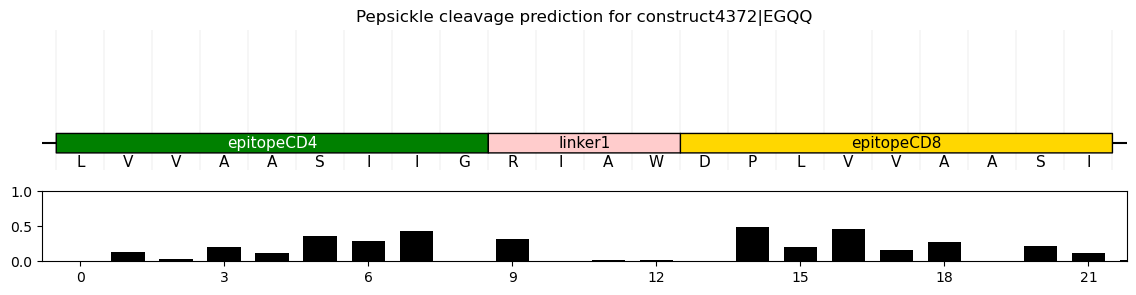

In [56]:
plot_seqCleavage(constructELE,worst_construct[2],tag=f"{worst_construct[0]}")

## Prediccion de clivado para Top5 secuencias (score de procesamiento). Diseño CALNN-L-E-L-E

In [143]:
cleavage_LELE_df = pd.read_csv("../results/Q76R36_top95q_multi_cleavage_results.csv")
fasta_constructs_LELE = SeqIO.to_dict(SeqIO.parse("../results/Q76R36_top95q_multi_toextend_5000.fasta", "fasta"))

In [144]:
seq_scores = []
for protid, protdf in cleavage_LELE_df.groupby("prot_id"):
    segments= [('Linker1', 5),('Linker1', 4),('Epitope1',9),('Linker2', 4), ('Epitope2', 9)]

    pred = protdf.prediction
    vax_process_score = calculate_cleavage_score(pred, segments)
    seq_scores.append((protid,vax_process_score, protdf))
construct_scored_LELE = sorted(seq_scores, key=lambda x: x[1],reverse=True)


In [146]:
q95_LELE = pd.DataFrame([s[1] for s in construct_scored_LELE]).quantile(0.95)[0]
print(q95_LELE)
construct_LELE_scored_q95 = list(filter(lambda x: x[1]>=q95_LELE,construct_scored_LELE))

-9.543720198404383


construct8297|THMW CALNNTHMWLVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):3321.91 pI: 6.74 Instability Index: 10.92 GRAVY: 1.090
construct6394|ETWW CALNNETWWLVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):3368.90 pI: 4.37 Instability Index: 8.81 GRAVY: 0.990
construct9789|TWSM CALNNTWSMLVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):3271.85 pI: 5.83 Instability Index: 2.09 GRAVY: 1.168
construct9669|EWTM CALNNEWTMLVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):3313.89 pI: 4.37 Instability Index: -0.02 GRAVY: 1.081
construct5446|EYRM CALNNEYRMLVVAASIIGRLSWDPLVVAASI
Molecular Weight (Da):3345.93 pI: 6.06 Instability Index: 4.22 GRAVY: 0.945


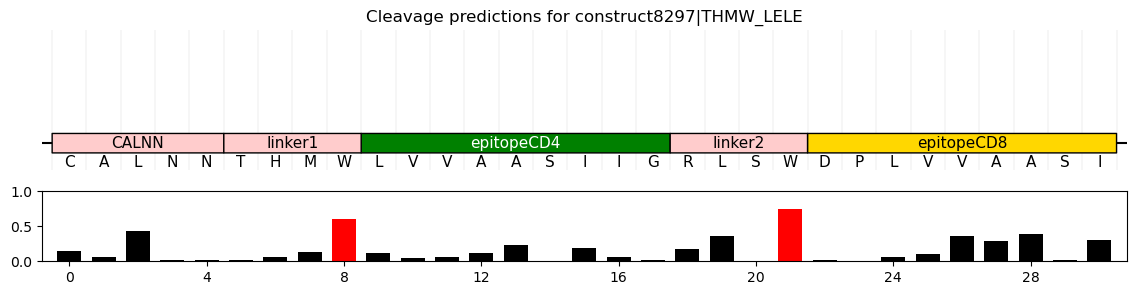

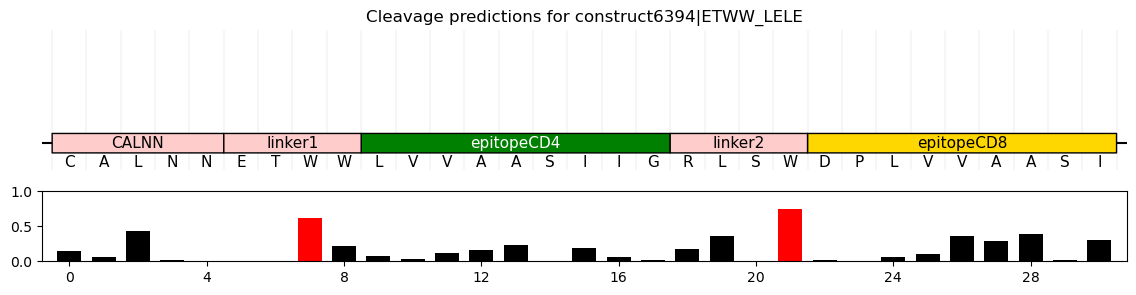

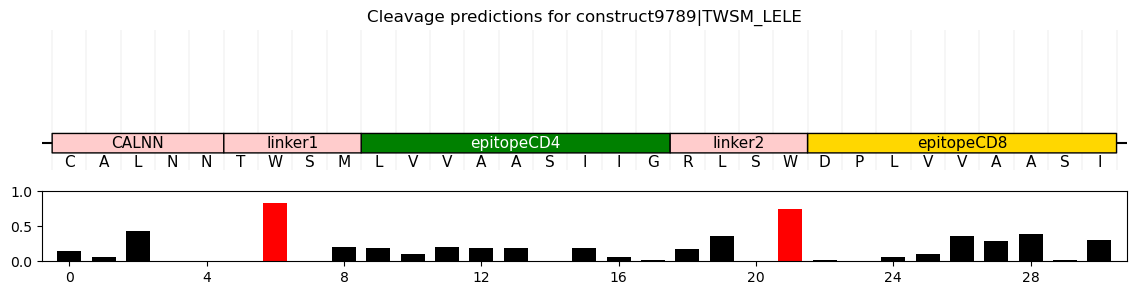

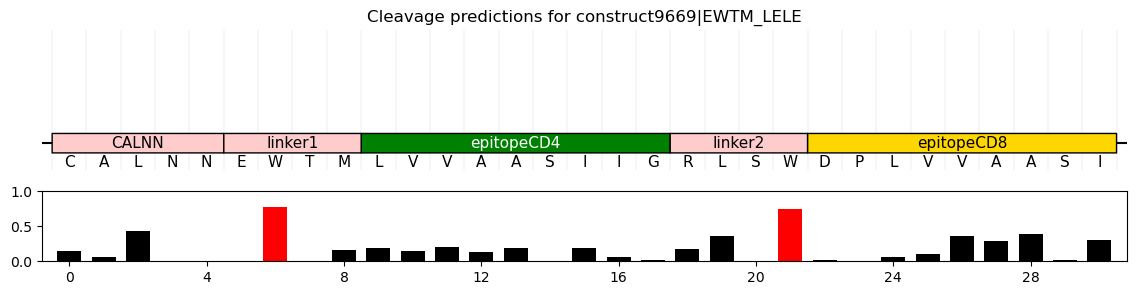

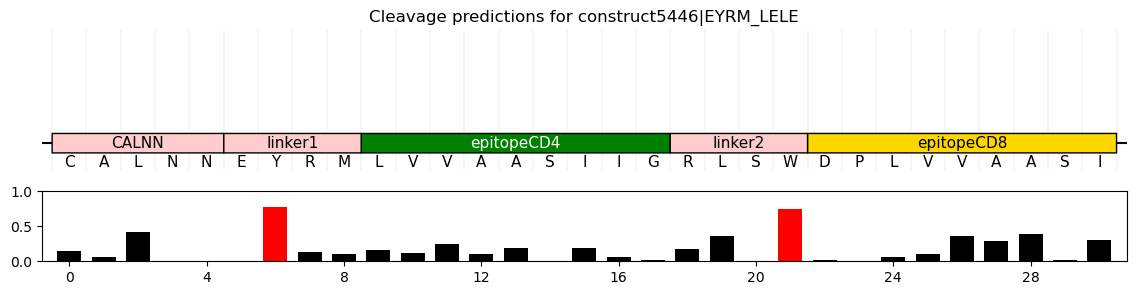

In [152]:
# plot top 5 
for data in construct_LELE_scored_q95[:5]:
    seqname = data[0]
    seqscore = round(data[1],4)
    sequence = str(fasta_constructs_LELE[seqname].seq)
    
    constructELE = dict()
    constructELE["CALNN"] = sequence[:5]
    constructELE["linker1"] = sequence[5:5+4]
    if sequence[5+4:].startswith("LVVAASIIG"):
        constructELE["epitopeCD4"] = sequence[5+4:5+4+9]
        constructELE["linker2"] = sequence[5+4+9:5+4+9+4]
        constructELE["epitopeCD8"] = sequence[5+4+9+4:5+4+9+4+9]
    else:
        constructELE["epitopeCD8"] = sequence[5+4:5+4+9]
        constructELE["linker2"] = sequence[5+4+9:5+4+9+4]
        constructELE["epitopeCD4"] = sequence[5+4+9+4:5+4+9+4+9]
    
    properties = analyze_vaccine_candidate(sequence)
    if properties[2] < 40 and properties[3] <= 1.7:
        print(seqname, sequence)
        plot_seqCleavage(constructELE, data[2], tag=f"{seqname}_LELE")
        print(f"Molecular Weight (Da):{properties[0]:.2f}",
        f"pI: {properties[1]:.2f}",
        f"Instability Index: {properties[2]:.2f}",
        f"GRAVY: {properties[3]:.3f}")

(array([  1.,   4.,   5.,   7.,  16.,  14.,  15.,  31.,  37.,  43.,  45.,
         52.,  69.,  78.,  84.,  84., 108., 143., 188., 223., 294., 347.,
        426., 471., 561., 571., 597., 643., 724., 737., 706., 736., 520.,
        515., 393., 276., 136.,  69.,  27.,  10.]),
 array([-13.88337175, -13.75961861, -13.63586547, -13.51211234,
        -13.3883592 , -13.26460607, -13.14085293, -13.0170998 ,
        -12.89334666, -12.76959352, -12.64584039, -12.52208725,
        -12.39833412, -12.27458098, -12.15082784, -12.02707471,
        -11.90332157, -11.77956844, -11.6558153 , -11.53206217,
        -11.40830903, -11.28455589, -11.16080276, -11.03704962,
        -10.91329649, -10.78954335, -10.66579021, -10.54203708,
        -10.41828394, -10.29453081, -10.17077767, -10.04702454,
         -9.9232714 ,  -9.79951826,  -9.67576513,  -9.55201199,
         -9.42825886,  -9.30450572,  -9.18075259,  -9.05699945,
         -8.93324631]),
 <BarContainer object of 40 artists>)

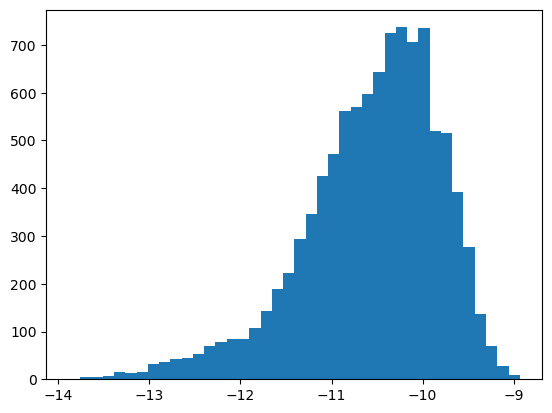

In [151]:
plt.hist([s[1] for s in construct_scored_LELE],bins=40)